# CDS 4003 - Report: Data Preparation & Assessment (CLO2)
**Project:** Predicting Road Accident Duration and Severity for Logistics Route Planning
**Dataset:** US Accidents (2016-2023), Kaggle `sobhanmoosavi/us-accidents`, file `US_Accidents_March23_sampled_500k.csv`
**Targets:** `Severity` (4 classes) and `Duration_Minutes` (built from the timestamps)

This notebook follows the same four parts as the report: 1. Data Import, 2. Data Understanding, 3. Data Preparation, 4. Documentation.
The result is `US_Accidents_clean.csv`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs('figs', exist_ok=True)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 100)

BLUE, GREY, RED = '#2f6db5', '#9aa5b1', '#c0392b'
def save(name):
    plt.tight_layout()
    plt.savefig(f'figs/{name}.png', dpi=160)
    plt.show()

# 1. Data Import

## 1.1 Source and loading
We load the CSV file with `pd.read_csv`. `low_memory=False` makes pandas read each column in one piece, so the types are not guessed chunk by chunk.
We keep this copy as `raw` and never change it. All later steps work on copies.

In [2]:
raw = pd.read_csv('../data/US_Accidents_March23_sampled_500k.csv', low_memory=False)
print('rows, columns:', raw.shape)
raw.head(3).T.head(46)

rows, columns: (500000, 46)


,0,1,2
ID,A-2047758,A-4694324,A-5006183
Source,Source2,Source1,Source1
Severity,2,2,2
Start_Time,2019-06-12 10:10:56,2022-12-03 23:37:14.000000000,2022-08-20 13:13:00.000000000
End_Time,2019-06-12 10:55:58,2022-12-04 01:56:53.000000000,2022-08-20 15:22:45.000000000
Start_Lat,30.641211,38.990562,34.661189
Start_Lng,-91.153481,-77.39907,-120.492822
End_Lat,NaN,38.990037,34.661189
End_Lng,NaN,-77.398282,-120.492442
Distance(mi),0.0,0.056,0.022


Some Description texts contain characters that can break an import (a `#` or a backslash). We check that pandas kept those records whole: the row count must still be 500,000 and the last column must be filled for these records.

In [3]:
has_hash = raw['Description'].str.contains('#', regex=False, na=False)
has_backslash = raw['Description'].str.contains('\\', regex=False, na=False)
print('Descriptions with #          :', int(has_hash.sum()))
print('Descriptions with a backslash:', int(has_backslash.sum()))
print('rows loaded                  :', len(raw))
print('Sunrise_Sunset filled in those # records:', int(raw.loc[has_hash, 'Sunrise_Sunset'].notna().sum()), 'of', int(has_hash.sum()))

Descriptions with #          : 7929
Descriptions with a backslash: 94
rows loaded                  : 500000
Sunrise_Sunset filled in those # records: 7928 of 7929


## 1.2 Data types
pandas gives each column a type when it reads the file. The three timestamps and the text columns come in as text (`object`/`str`), so we convert the timestamps ourselves in Section 3.

In [4]:
type_counts = raw.dtypes.astype(str).replace({'str': 'object'}).value_counts()
print(type_counts)
print()
print('True/False flags :', [c for c in raw.columns if raw[c].dtype == bool])
print('Real (float)     :', [c for c in raw.columns if raw[c].dtype == 'float64'])
print('Integer          :', [c for c in raw.columns if str(raw[c].dtype).startswith('int')])
print('Date columns     :', ['Start_Time', 'End_Time', 'Weather_Timestamp'], '(read as text)')

object     20
bool       13
float64    12
int64       1
Name: count, dtype: int64

True/False flags : ['Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Turning_Loop']
Real (float)     : ['Start_Lat', 'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']
Integer          : ['Severity']
Date columns     : ['Start_Time', 'End_Time', 'Weather_Timestamp'] (read as text)


# 2. Data Understanding
We check the five quality problems from Chapter 3 (missing values, noise, inconsistencies, redundancy, attributes with no variation) and then data leakage.

## 2.1 Exploring the raw data
First look at the target `Severity`: how many records fall in each of the four classes.

Severity
1      4274
2    398142
3     84520
4     13064


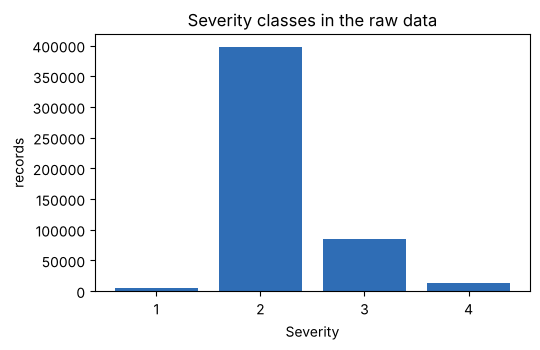

In [5]:
sev = raw['Severity'].value_counts().sort_index()
print(sev.to_string())
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(sev.index.astype(str), sev.values, color=BLUE)
ax.set_xlabel('Severity'); ax.set_ylabel('records'); ax.set_title('Severity classes in the raw data')
save('04_severity')

## 2.2.1 Missing values

In [6]:
missing = raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
miss_table = pd.DataFrame({'missing': missing, 'percent': (missing / len(raw) * 100).round(2)})
print('missing cells:', int(raw.isna().sum().sum()), 'in', len(missing), 'of', raw.shape[1], 'attributes')
miss_table

missing cells: 829873 in 22 of 46 attributes


,missing,percent
End_Lat,220377,44.08
End_Lng,220377,44.08
Precipitation(in),142616,28.52
Wind_Chill(F),129017,25.80
Wind_Speed(mph),36987,7.40
Visibility(mi),11291,2.26
Wind_Direction,11197,2.24
Humidity(%),11130,2.23
Weather_Condition,11101,2.22
Temperature(F),10466,2.09


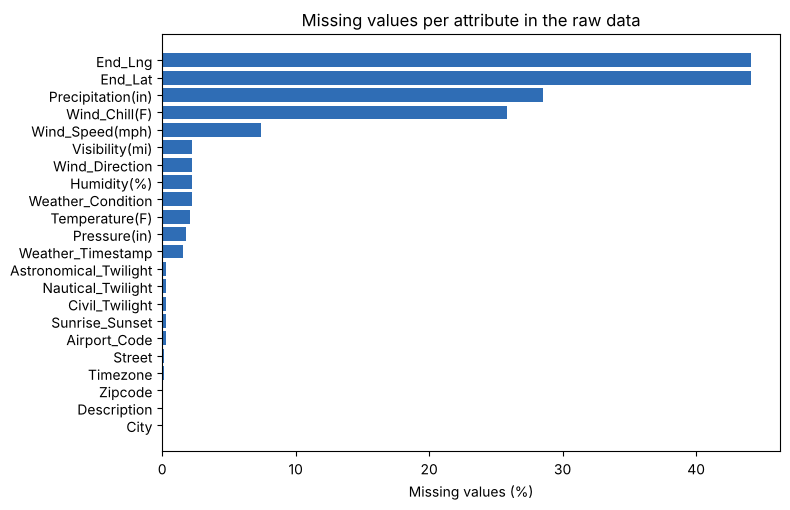

In [7]:
fig, ax = plt.subplots(figsize=(8, 5.2))
m = miss_table.sort_values('percent')
ax.barh(m.index, m['percent'], color=BLUE)
ax.set_xlabel('Missing values (%)')
ax.set_title('Missing values per attribute in the raw data')
save('01_missing_raw')

Two of the large gaps look like they have a reason, so we check it. We also look at how many records of each source lack `End_Lat`, and how the missing `Wind_Chill(F)` depends on the temperature.

In [8]:
print('End_Lat missing share by Source:')
print((raw['End_Lat'].isna().groupby(raw['Source']).mean() * 100).round(1).to_string())
warm = raw['Temperature(F)'] > 50
cool = raw['Temperature(F)'] <= 50
print()
print('Wind_Chill missing when temp > 50F :', round(raw.loc[warm, 'Wind_Chill(F)'].isna().mean() * 100, 1), '%')
print('Wind_Chill missing when temp <= 50F:', round(raw.loc[cool, 'Wind_Chill(F)'].isna().mean() * 100, 1), '%')

End_Lat missing share by Source:
Source
Source1      0.0
Source2    100.0
Source3    100.0

Wind_Chill missing when temp > 50F : 29.2 %
Wind_Chill missing when temp <= 50F: 10.7 %


## 2.2.2 Noise: impossible and extreme values
First we look at the weather attributes. Some values are not possible for real weather.

In [9]:
weather = ['Temperature(F)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Humidity(%)', 'Precipitation(in)']
raw[weather].describe().T[['min', 'mean', 'max']].round(2)

,min,mean,max
Temperature(F),-77.80,61.65,207.00
Pressure(in),0.12,29.54,38.44
Visibility(mi),0.00,9.09,130.00
Wind_Speed(mph),0.00,7.68,822.80
Humidity(%),1.00,64.83,100.00
Precipitation(in),0.00,0.01,10.13


We use plausible limits based on physical facts: temperature -60 to 135 F, wind speed 0 to 200 mph, pressure 20 to 33 in, visibility 0 to 50 mi.
These limits are our own assumption, not values from the data source.

In [10]:
LIMITS = {'Temperature(F)': (-60, 135), 'Wind_Speed(mph)': (0, 200),
          'Pressure(in)': (20, 33), 'Visibility(mi)': (0, 50)}
impossible_raw = {c: int(((raw[c] < lo) | (raw[c] > hi)).sum()) for c, (lo, hi) in LIMITS.items()}
print(impossible_raw, 'total', sum(impossible_raw.values()))
print('Temperature values outside the limits:', sorted(raw.loc[(raw['Temperature(F)'] < -60) | (raw['Temperature(F)'] > 135), 'Temperature(F)']))

{'Temperature(F)': 4, 'Wind_Speed(mph)': 3, 'Pressure(in)': 24, 'Visibility(mi)': 74} total 105
Temperature values outside the limits: [-77.8, 140.0, 196.0, 207.0]


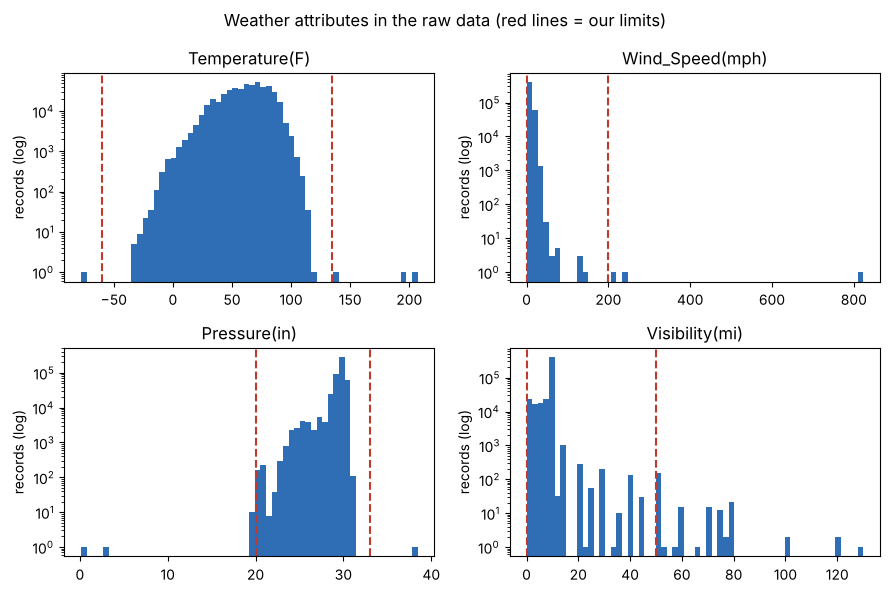

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, (c, (lo, hi)) in zip(axes.ravel(), LIMITS.items()):
    ax.hist(raw[c].dropna(), bins=60, color=BLUE)
    ax.axvline(lo, color=RED, ls='--'); ax.axvline(hi, color=RED, ls='--')
    ax.set_yscale('log'); ax.set_title(c); ax.set_ylabel('records (log)')
fig.suptitle('Weather attributes in the raw data (red lines = our limits)')
save('02_impossible_weather')

Next is the duration. `Duration_Minutes` is not in the file, so we calculate it from `End_Time` minus `Start_Time`.
We cut the timestamp text at 19 characters (`yyyy-mm-dd hh:mm:ss`) because some values have extra decimals.

In [12]:
start = pd.to_datetime(raw['Start_Time'].str[:19])
end = pd.to_datetime(raw['End_Time'].str[:19])
dur = (end - start).dt.total_seconds() / 60
print('min, max (minutes):', round(dur.min(), 2), round(dur.max(), 1), '= about', round(dur.max() / 60 / 24 / 365, 1), 'years')
print('shorter than 5 min:', int((dur < 5).sum()))
print('longer than 24 h  :', int((dur > 1440).sum()))
q1, q3 = dur.quantile([.25, .75])
iqr_cut = q3 + 1.5 * (q3 - q1)
print('IQR rule cut-off  :', round(iqr_cut, 1), 'min ->', round((dur > iqr_cut).mean() * 100, 1), '% of records would be removed')
print('Source of the 2,199 records above 24 h:')
print(raw.loc[dur > 1440, 'Source'].value_counts())

min, max (minutes): 2.5 2236405.8 = about 4.3 years
shorter than 5 min: 5
longer than 24 h  : 2199
IQR rule cut-off  : 265.8 min -> 9.5 % of records would be removed
Source of the 2,199 records above 24 h:
Source
Source1    2171
Source2      28
Name: count, dtype: int64


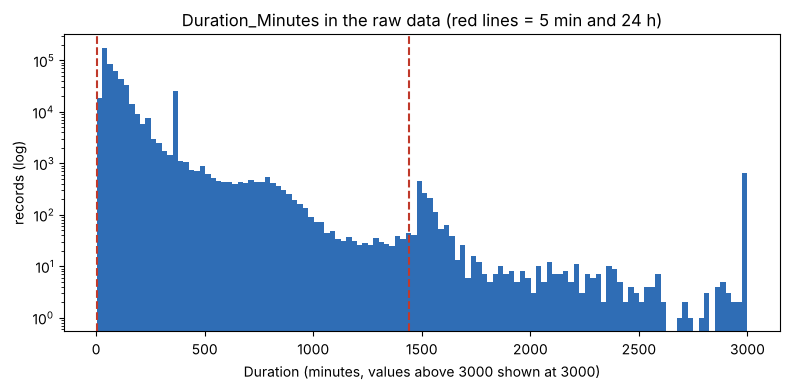

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(dur.clip(upper=3000), bins=120, color=BLUE)
ax.axvline(5, color=RED, ls='--'); ax.axvline(1440, color=RED, ls='--')
ax.set_yscale('log'); ax.set_xlabel('Duration (minutes, values above 3000 shown at 3000)'); ax.set_ylabel('records (log)')
ax.set_title('Duration_Minutes in the raw data (red lines = 5 min and 24 h)')
save('03_duration_raw')

## 2.2.3 Inconsistencies: the same value written two ways

In [14]:
wd = raw['Wind_Direction'].value_counts()
print('Wind_Direction labels:', len(wd))
print(wd.to_string())
print()
print('Weather_Condition has', raw['Weather_Condition'].nunique(), 'different values')

Wind_Direction labels: 24
Wind_Direction
CALM        62259
S           27182
W           24976
SSW         24805
WNW         24328
Calm        24022
NW          23889
SW          23648
WSW         22869
SSE         22644
NNW         21579
N           19947
SE          19156
E           17971
ESE         17185
NE          16880
ENE         16683
NNE         16639
VAR         16232
South       11371
West        10703
North        9857
Variable     7406
East         6572

Weather_Condition has 108 different values


## 2.2.4 Redundancy: duplicates and repeated information

In [15]:
print('ID is unique:', raw['ID'].is_unique)
print('exact duplicates (all columns, with ID):', int(raw.duplicated().sum()))
print('exact duplicates when ID is left out   :', int(raw.drop(columns=['ID']).duplicated().sum()))

ID is unique: True


exact duplicates (all columns, with ID): 0


exact duplicates when ID is left out   : 439


In [16]:
for c in ['Civil_Twilight', 'Nautical_Twilight', 'Astronomical_Twilight']:
    both = raw[c].notna() & raw['Sunrise_Sunset'].notna()
    print(f'{c} agrees with Sunrise_Sunset:', round((raw.loc[both, c] == raw.loc[both, 'Sunrise_Sunset']).mean() * 100, 1), '%')

# Wind_Chill against the standard formula (T <= 50 F, wind >= 3 mph)
T_, V_ = raw['Temperature(F)'], raw['Wind_Speed(mph)']
formula = 35.74 + 0.6215 * T_ - 35.75 * V_ ** 0.16 + 0.4275 * T_ * V_ ** 0.16
ok = (T_ <= 50) & (V_ >= 3) & raw['Wind_Chill(F)'].notna()
print()
print('records used for the formula check:', int(ok.sum()))
print('correlation with the formula      :', round(raw.loc[ok, 'Wind_Chill(F)'].corr(formula[ok]), 3))
print('Wind_Chill missing:', round(raw['Wind_Chill(F)'].isna().mean() * 100, 1), '%')
print('End_Lat / End_Lng missing:', int(raw['End_Lat'].isna().sum()), 'records =', round(raw['End_Lat'].isna().mean() * 100), '%')

Civil_Twilight agrees with Sunrise_Sunset: 95.3 %
Nautical_Twilight agrees with Sunrise_Sunset: 90.4 %


Astronomical_Twilight agrees with Sunrise_Sunset: 86.4 %

records used for the formula check: 97596
correlation with the formula      : 0.998
Wind_Chill missing: 25.8 %
End_Lat / End_Lng missing: 220377 records = 44 %


## 2.2.5 Attributes with no variation

In [17]:
print('Country values       :', list(raw['Country'].unique()))
print('Turning_Loop True    :', int(raw['Turning_Loop'].sum()))
print('Roundabout True      :', int(raw['Roundabout'].sum()))
print('Street unique values :', raw['Street'].nunique())
print('Zipcode unique values:', raw['Zipcode'].nunique())
print('Source values        :', list(raw['Source'].unique()))

Country values       : ['US']
Turning_Loop True    : 0
Roundabout True      : 13
Street unique values : 88272
Zipcode unique values: 127804
Source values        : ['Source2', 'Source1', 'Source3']


## 2.2.6 Data leakage
The model has to predict the duration and the severity when the accident is reported. Four attributes describe how the accident ended, so they are not known at that time: `End_Time`, `End_Lat`, `End_Lng` and `Distance(mi)` (the length of road affected).
`Distance(mi)` is the unclear case, because it could be estimated later by the dispatcher, but we exclude it to be safe.

# 3. Data Preparation

## 3.1 Overview
Two rules for the whole part: we only delete a row when the whole record is unusable (impossible duration or exact duplicate). If only one value is bad, we set it to missing and fill it in.

## 3.2 Step 1: Construct the regression target

In [18]:
df = raw.copy()
df['Start_Time'] = pd.to_datetime(df['Start_Time'].str[:19])
df['End_Time'] = pd.to_datetime(df['End_Time'].str[:19])
df['Duration_Minutes'] = (df['End_Time'] - df['Start_Time']).dt.total_seconds() / 60
print(df.shape)

(500000, 47)


## 3.3 Step 2: Remove extreme durations
We tried the IQR rule first, but it cuts at about 266 minutes and would remove 9.5% of the records, including the long closures that matter most.
Instead we keep durations from 5 minutes to 24 hours. This limit is our assumption (an accident still active after a full day is most likely a reporting error).

In [19]:
too_short = int((df['Duration_Minutes'] < 5).sum())
too_long = int((df['Duration_Minutes'] > 1440).sum())
df = df[(df['Duration_Minutes'] >= 5) & (df['Duration_Minutes'] <= 1440)].copy()
print('removed shorter than 5 min:', too_short, '| longer than 24 h:', too_long, '| total:', too_short + too_long)
print('records left:', len(df))

removed shorter than 5 min: 5 | longer than 24 h: 2199 | total: 2204
records left: 497796


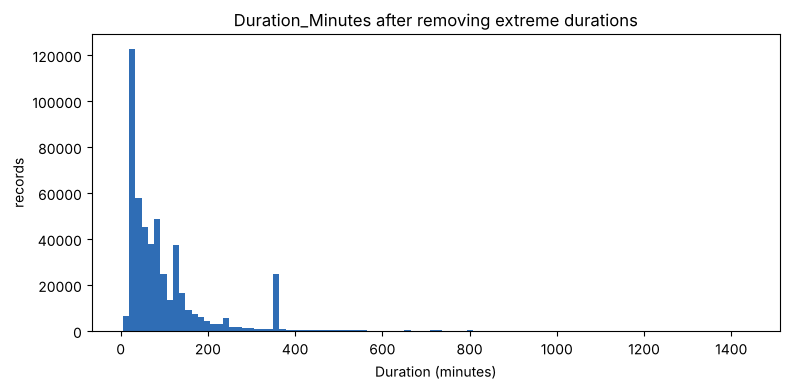

count    497796.0
mean        108.2
std         123.7
min           5.0
25%          31.3
50%          74.8
75%         124.6
max        1440.0


In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df['Duration_Minutes'], bins=100, color=BLUE)
ax.set_xlabel('Duration (minutes)'); ax.set_ylabel('records'); ax.set_title('Duration_Minutes after removing extreme durations')
save('05_duration_clean')
print(df['Duration_Minutes'].describe().round(1).to_string())

## 3.4 Step 3: Select relevant attributes
We drop 18 attributes:
- `ID` (only a row key), `Source` (only tells which API reported the accident), `Description` (free text)
- `Street` and `Zipcode` (too many different values), `Airport_Code`, `Weather_Timestamp`
- `Country` and `Turning_Loop` (same value in every record) and `Roundabout` (True in only 13 records)
- `End_Time`, `End_Lat`, `End_Lng`, `Distance(mi)` (data leakage)
- `Civil_Twilight`, `Nautical_Twilight`, `Astronomical_Twilight` (repeat `Sunrise_Sunset`)
- `Wind_Chill(F)` (almost a function of temperature and wind speed, and 25.8% missing)

`Start_Time` and `Weather_Condition` stay for now because the next steps need them.

In [21]:
print('Median duration by Source (after the duration filter):')
print(df.groupby('Source')['Duration_Minutes'].median().round(1).to_string())
print()
print('End_Lat present by Source:')
print(df['End_Lat'].notna().groupby(df['Source']).mean().round(2).to_string())
print()
print('Spearman correlation with Duration_Minutes (numeric attributes):')
numcols = ['Distance(mi)', 'Start_Lat', 'Start_Lng', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']
corr = df[numcols + ['Duration_Minutes']].corr(method='spearman')['Duration_Minutes']
print(corr.drop('Duration_Minutes').round(3).to_string())
print()
drop_cols = ['ID', 'Source', 'Description', 'Street', 'Zipcode', 'Airport_Code', 'Weather_Timestamp',
             'Country', 'Turning_Loop', 'Roundabout',
             'End_Time', 'End_Lat', 'End_Lng', 'Distance(mi)',
             'Civil_Twilight', 'Nautical_Twilight', 'Astronomical_Twilight', 'Wind_Chill(F)']
print(len(drop_cols), 'attributes dropped')
df = df.drop(columns=drop_cols)
print(df.shape)

Median duration by Source (after the duration filter):
Source
Source1    105.0
Source2     44.6
Source3     45.0

End_Lat present by Source:
Source
Source1    1.0
Source2    0.0
Source3    0.0

Spearman correlation with Duration_Minutes (numeric attributes):


Distance(mi)         0.403
Start_Lat            0.015
Start_Lng           -0.011
Temperature(F)      -0.027
Humidity(%)         -0.021
Pressure(in)        -0.133
Visibility(mi)       0.010
Wind_Speed(mph)     -0.039
Precipitation(in)   -0.058

18 attributes dropped
(497796, 29)


## 3.5 Step 4: Clean impossible values
Values outside the limits from Section 2.2 are set to missing. We keep the record, because its other attributes are valid. The gaps are filled in Step 7.

In [22]:
for c, (lo, hi) in LIMITS.items():
    bad = (df[c] < lo) | (df[c] > hi)
    print(f'{c}: {int(bad.sum())} set to missing')
    df.loc[bad, c] = np.nan

Temperature(F): 4 set to missing
Wind_Speed(mph): 3 set to missing
Pressure(in): 24 set to missing
Visibility(mi): 74 set to missing


## 3.6 Step 5: Standardise Wind_Direction
Six directions are written in two ways each (for example `CALM` and `Calm`). We change the abbreviations to the full word. Compass points such as NNE and SW stay as they are, because they are different directions.

In [23]:
wind_map = {'CALM': 'Calm', 'VAR': 'Variable', 'N': 'North', 'S': 'South', 'E': 'East', 'W': 'West'}
before = df['Wind_Direction'].nunique()
df['Wind_Direction'] = df['Wind_Direction'].replace(wind_map)
print('labels:', before, '->', df['Wind_Direction'].nunique())

labels: 24 -> 18


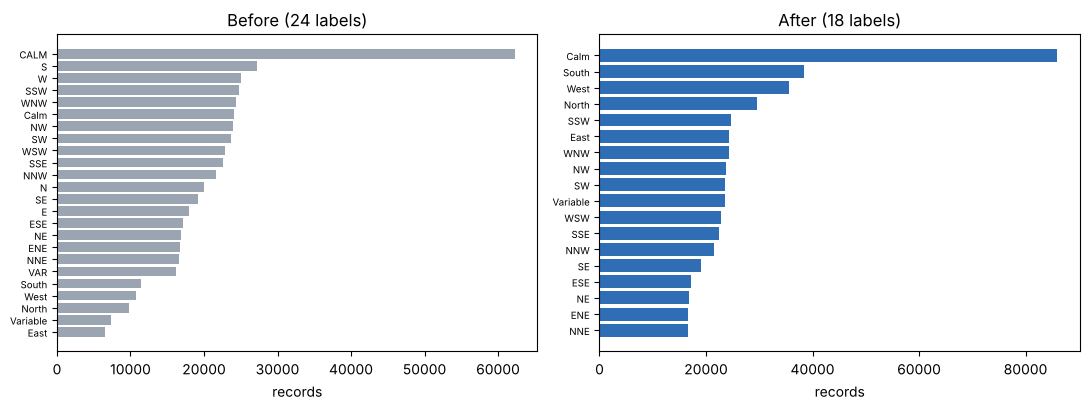

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=False)
raw_wd = raw['Wind_Direction'].value_counts()
new_wd = df['Wind_Direction'].value_counts()
axes[0].barh(raw_wd.index[::-1], raw_wd.values[::-1], color=GREY); axes[0].set_title(f'Before ({len(raw_wd)} labels)')
axes[1].barh(new_wd.index[::-1], new_wd.values[::-1], color=BLUE); axes[1].set_title(f'After ({len(new_wd)} labels)')
for ax in axes: ax.tick_params(axis='y', labelsize=7); ax.set_xlabel('records')
save('06_wind_direction')

## 3.7 Step 6: Construct new attributes
A model cannot use a timestamp directly, so we build new attributes from `Start_Time`. We also group the 108 `Weather_Condition` values into 7 groups.

In [25]:
df['Hour'] = df['Start_Time'].dt.hour
df['Month'] = df['Start_Time'].dt.month
df['Year'] = df['Start_Time'].dt.year
df['DayOfWeek'] = df['Start_Time'].dt.day_name()
df['Is_Weekend'] = df['DayOfWeek'].isin(['Saturday', 'Sunday']).astype(int)
df['Is_RushHour'] = df['Hour'].isin([7, 8, 9, 16, 17, 18]).astype(int)
df['Season'] = np.select([df['Month'].isin([12, 1, 2]), df['Month'] <= 5, df['Month'] <= 8],
                         ['Winter', 'Spring', 'Summer'], default='Autumn')

poi = ['Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway',
       'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal']
df['POI_Count'] = df[poi].astype(int).sum(axis=1)
print(df[['Hour', 'Month', 'Year', 'DayOfWeek', 'Is_Weekend', 'Is_RushHour', 'Season', 'POI_Count']].head())

   Hour  Month  Year  DayOfWeek  Is_Weekend  Is_RushHour  Season  POI_Count
0    10      6  2019  Wednesday           0            0  Summer          1
1    23     12  2022   Saturday           1            0  Winter          0
2    13      8  2022   Saturday           1            0  Summer          1
3    17      2  2022     Monday           0            1  Winter          0
4     1     12  2020     Friday           0            0  Winter          0


For `Weather_Group` we lower-case the text and search for keywords in a fixed order, so the most severe condition wins (the last matching group overwrites the earlier ones).

In [26]:
cond = df['Weather_Condition'].str.lower().fillna('')
groups = [('Clear', ('fair', 'clear')),
          ('Cloudy', ('cloud', 'overcast')),
          ('Low Visibility', ('fog', 'mist', 'haze', 'smoke', 'dust', 'sand')),
          ('Rain', ('rain', 'drizzle', 'shower')),
          ('Snow/Ice', ('snow', 'sleet', 'wintry', 'ice', 'hail', 'freezing')),
          ('Thunderstorm', ('thunder', 't-storm', 'tornado'))]
weather_group = pd.Series('Other', index=df.index)
for name, words in groups:
    weather_group[cond.apply(lambda s: any(w in s for w in words))] = name
weather_group[df['Weather_Condition'].isna()] = np.nan
df['Weather_Group'] = weather_group
print(df['Weather_Group'].value_counts(dropna=False).to_string())

Weather_Group
Clear             219653
Cloudy            203708
Rain               33016
Low Visibility     13075
Snow/Ice           11387
NaN                11050
Thunderstorm        5700
Other                207


Hour
7     37909
8     37536
16    37284
17    36971
15    34011
14    28862
18    27828
6     25996
hour 9: 23443 | hour 12: 22866 | hour 6: 25996 | hour 15: 34011


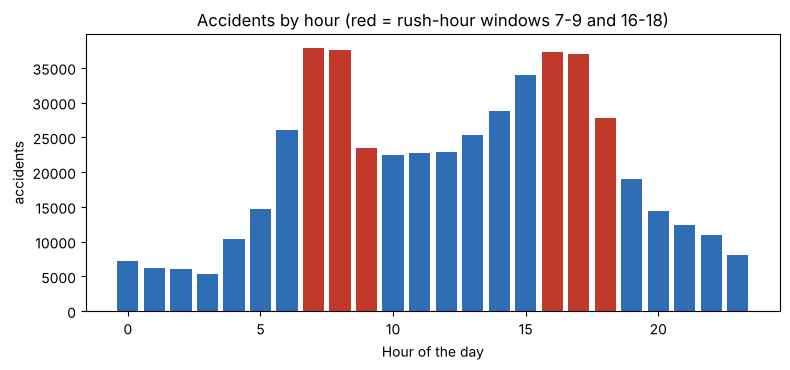

In [27]:
by_hour = df.groupby('Hour').size()
print(by_hour.sort_values(ascending=False).head(8).to_string())
print('hour 9:', by_hour[9], '| hour 12:', by_hour[12], '| hour 6:', by_hour[6], '| hour 15:', by_hour[15])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(by_hour.index, by_hour.values, color=[RED if h in (7, 8, 9, 16, 17, 18) else BLUE for h in by_hour.index])
ax.set_xlabel('Hour of the day'); ax.set_ylabel('accidents')
ax.set_title('Accidents by hour (red = rush-hour windows 7-9 and 16-18)')
save('07_hour')

## 3.8 Step 7: Handle missing values
We choose the method per attribute (Chapter 4):
- `Precipitation(in)`: missing means no rain was reported, so it is set to 0.
- Numeric attributes: the mean.
- Text attributes: the most frequent value (the mode).

We use the mean for the numeric weather attributes. The table below compares it with the median, and the two are close, so the choice changes little. The values are taken from the whole file, which is a small limit: when we build models, they should be fitted on the training split only.

In [28]:
num_fill = ['Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)']
print(pd.DataFrame({'mean': df[num_fill].mean(), 'median': df[num_fill].median()}).round(2))
print('Precipitation(in) median:', df['Precipitation(in)'].median())
print()
mv_before = df.isna().sum()
mv_before = mv_before[mv_before > 0]
mv_share = (mv_before / len(df) * 100).round(2)
print((mv_share).to_string())
print()
print('missing cells before:', int(mv_before.sum()))
print(mv_before.to_string())

                  mean  median
Temperature(F)   61.66   64.00
Humidity(%)      64.84   67.00
Pressure(in)     29.54   29.86
Visibility(mi)    9.08   10.00
Wind_Speed(mph)   7.68    7.00
Precipitation(in) median: 0.0

City                  0.00
Timezone              0.10
Temperature(F)        2.09
Humidity(%)           2.23
Pressure(in)          1.79
Visibility(mi)        2.27
Wind_Direction        2.24
Wind_Speed(mph)       7.42
Precipitation(in)    28.63
Weather_Condition     2.22
Sunrise_Sunset        0.29
Weather_Group         2.22

missing cells before: 256367
City                     19
Timezone                500
Temperature(F)        10422
Humidity(%)           11080
Pressure(in)           8913
Visibility(mi)        11311
Wind_Direction        11128
Wind_Speed(mph)       36912
Precipitation(in)    142527
Weather_Condition     11050
Sunrise_Sunset         1455
Weather_Group         11050


In [29]:
df['Precipitation(in)'] = df['Precipitation(in)'].fillna(0)
fill_values = {}
for c in df.columns:
    if c in ('Start_Time', 'Precipitation(in)'):
        continue
    if df[c].isna().any():
        is_num = pd.api.types.is_numeric_dtype(df[c])
        value = df[c].mean() if is_num else df[c].mode().iloc[0]
        fill_values[c] = round(float(value), 4) if not isinstance(value, str) else value
        df[c] = df[c].fillna(value)
print(fill_values)
print('missing cells after:', int(df.isna().sum().sum()))

{'City': 'Miami', 'Timezone': 'US/Eastern', 'Temperature(F)': 61.6563, 'Humidity(%)': 64.8371, 'Pressure(in)': 29.5398, 'Visibility(mi)': 9.0819, 'Wind_Direction': 'Calm', 'Wind_Speed(mph)': 7.6788, 'Weather_Condition': 'Fair', 'Sunrise_Sunset': 'Day', 'Weather_Group': 'Clear'}
missing cells after: 0


## 3.9 Step 8: Drop the replaced attributes
`Weather_Condition` and `Start_Time` are replaced by `Weather_Group` and the time attributes.

In [30]:
df = df.drop(columns=['Weather_Condition', 'Start_Time'])
print(df.shape)

(497796, 36)


## 3.10 Step 9: Remove exact duplicates
After the changes above, some records are identical in all attributes. We remove them and keep the first one.

In [31]:
n_dup = int(df.duplicated().sum())
dup_index = df.index[df.duplicated(keep='first')]
print('duplicates found:', n_dup)

# check them against the raw file
raw_dup_no_id = raw.drop(columns=['ID']).duplicated(keep='first')
group = df.groupby(list(df.columns), sort=False).ngroup()
first_index = pd.Series(df.index, index=df.index).groupby(group).transform('first')
same_start = raw.loc[dup_index, 'Start_Time'].values == raw.loc[first_index.loc[dup_index].values, 'Start_Time'].values
same_source = raw.loc[dup_index, 'Source'].values == raw.loc[first_index.loc[dup_index].values, 'Source'].values
print('exact copies in all 45 raw attributes except ID:', int(raw_dup_no_id.loc[dup_index].sum()))
print('same raw Start_Time as the kept record        :', int(same_start.sum()))
print('same Source as the kept record                :', int(same_source.sum()))

duplicates found: 699


exact copies in all 45 raw attributes except ID: 431
same raw Start_Time as the kept record        : 561
same Source as the kept record                : 699


In [32]:
clean = df.drop_duplicates().copy()
print('records left:', len(clean))

records left: 497097


## 3.11 Step 10: Integration, encoding and normalisation
Integration: we did not join any dataset, because the publisher already joined the weather, road-feature and daylight data to each accident.

Encoding and normalisation (Chapter 4, Step 6): we show it on a separate copy called `model_ready`. It is not saved, because the encoding and scaling should be fitted on the training split when the models are built.
Columns with many values (`City`, `County`, `State`) are left for the modelling stage.

In [33]:
model_ready = clean.copy()
model_ready[poi] = model_ready[poi].astype(int)

nominal = ['Timezone', 'Wind_Direction', 'Sunrise_Sunset', 'Weather_Group', 'Season', 'DayOfWeek']
model_ready = pd.get_dummies(model_ready, columns=nominal, dtype=int)

continuous = ['Start_Lat', 'Start_Lng', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)',
              'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)', 'POI_Count']
cont = model_ready[continuous]
model_ready[continuous] = (cont - cont.mean()) / cont.std()

print('dummy columns created:', model_ready.shape[1] - (clean.shape[1] - len(nominal)))
print('values per nominal attribute:', {c: int(clean[c].nunique()) for c in nominal})
print('City, County, State values  :', int(clean['City'].nunique()), int(clean['County'].nunique()), int(clean['State'].nunique()))
print('clean       :', clean.shape)
print('model_ready :', model_ready.shape)
print(model_ready[continuous].agg(['mean', 'std']).round(3).T)

dummy columns created: 42
values per nominal attribute: {'Timezone': 4, 'Wind_Direction': 18, 'Sunrise_Sunset': 2, 'Weather_Group': 7, 'Season': 4, 'DayOfWeek': 7}
City, County, State values  : 9466 1602 49
clean       : (497097, 36)
model_ready : (497097, 72)


                   mean  std
Start_Lat          -0.0  1.0
Start_Lng           0.0  1.0
Temperature(F)      0.0  1.0
Humidity(%)         0.0  1.0
Pressure(in)       -0.0  1.0
Visibility(mi)     -0.0  1.0
Wind_Speed(mph)     0.0  1.0
Precipitation(in)  -0.0  1.0
POI_Count           0.0  1.0


# 4. Documentation

## 4.1 Preparation log

In [34]:
log = pd.DataFrame([
    ['1', 'Construct', 'Duration_Minutes', 'End_Time minus Start_Time in minutes', 'Regression target is not in the file'],
    ['2', 'Clean', 'Duration_Minutes', 'Kept 5 to 1,440 minutes (2,204 records removed)', 'IQR rule would remove 9.5%; 24 h limit is an assumption'],
    ['3', 'Select', '18 attributes', 'Dropped', 'Keys, free text, constants, leakage, repeats'],
    ['4', 'Clean', '4 weather attributes', '105 impossible values set to missing', 'Limits based on physical facts (assumption)'],
    ['5', 'Format', 'Wind_Direction', '24 labels merged to 18', 'CALM and Calm are the same value'],
    ['6', 'Construct', '9 new attributes + Weather_Group', 'Hour, Month, Year, DayOfWeek, Is_Weekend, Is_RushHour, Season, POI_Count, Weather_Group', 'Models cannot use timestamps or 108 text values'],
    ['7', 'Clean', '22 attributes with gaps', 'Precipitation = 0, mean for numbers, mode for text', 'Chapter 4 decision guide'],
    ['8', 'Select', 'Weather_Condition, Start_Time', 'Dropped', 'Replaced by the new attributes'],
    ['9', 'Clean', 'All 36 attributes', '699 exact duplicates removed', 'Identical records'],
    ['10', 'Integrate / Encode', 'model_ready copy', 'No join; dummy coding and z-score on a copy', 'Fitted on the training split later'],
], columns=['Step', 'Type', 'Attributes', 'Action', 'Reason'])
log

,Step,Type,Attributes,Action,Reason
0,1,Construct,Duration_Minutes,End_Time minus Start_Time in minutes,Regression target is not in the file
1,2,Clean,Duration_Minutes,"Kept 5 to 1,440 minutes (2,204 records removed)",IQR rule would remove 9.5%; 24 h limit is an a...
2,3,Select,18 attributes,Dropped,"Keys, free text, constants, leakage, repeats"
3,4,Clean,4 weather attributes,105 impossible values set to missing,Limits based on physical facts (assumption)
4,5,Format,Wind_Direction,24 labels merged to 18,CALM and Calm are the same value
5,6,Construct,9 new attributes + Weather_Group,"Hour, Month, Year, DayOfWeek, Is_Weekend, Is_R...",Models cannot use timestamps or 108 text values
6,7,Clean,22 attributes with gaps,"Precipitation = 0, mean for numbers, mode for ...",Chapter 4 decision guide
7,8,Select,"Weather_Condition, Start_Time",Dropped,Replaced by the new attributes
8,9,Clean,All 36 attributes,699 exact duplicates removed,Identical records
9,10,Integrate / Encode,model_ready copy,No join; dummy coding and z-score on a copy,Fitted on the training split later


## 4.2 Data quality before and after

In [35]:
summary = pd.DataFrame({
    'Raw data': [raw.shape[0], raw.shape[1], int(raw.isna().sum().sum()), int(raw.drop(columns=['ID']).duplicated().sum()),
                 sum(impossible_raw.values()), raw['Wind_Direction'].nunique()],
    'Clean data': [clean.shape[0], clean.shape[1], int(clean.isna().sum().sum()), int(clean.duplicated().sum()),
                   0, clean['Wind_Direction'].nunique()],
}, index=['Records', 'Attributes', 'Missing cells', 'Duplicates (raw: ID left out)', 'Impossible weather values', 'Wind_Direction labels'])
summary

,Raw data,Clean data
Records,500000,497097
Attributes,46,36
Missing cells,829873,0
Duplicates (raw: ID left out),439,0
Impossible weather values,105,0
Wind_Direction labels,24,18


In [36]:
print('Duration_Minutes in the clean data:', clean['Duration_Minutes'].min(), 'to', clean['Duration_Minutes'].max())
print('kept:', round(len(clean) / len(raw) * 100, 2), '%')
print('removed records:', len(raw) - len(clean), '= 2,204 extreme durations + 699 duplicates')
print('final shape    :', clean.shape)
print('columns        :', list(clean.columns))

Duration_Minutes in the clean data: 5.0 to 1440.0
kept: 99.42 %
removed records: 2903 = 2,204 extreme durations + 699 duplicates
final shape    : (497097, 36)
columns        : ['Severity', 'Start_Lat', 'Start_Lng', 'City', 'County', 'State', 'Timezone', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)', 'Precipitation(in)', 'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Sunrise_Sunset', 'Duration_Minutes', 'Hour', 'Month', 'Year', 'DayOfWeek', 'Is_Weekend', 'Is_RushHour', 'Season', 'POI_Count', 'Weather_Group']


## 4.3 Save the clean data

In [37]:
clean.to_csv('../data/US_Accidents_clean.csv', index=False)
check = pd.read_csv('../data/US_Accidents_clean.csv')
print(check.shape, '| missing:', int(check.isna().sum().sum()), '| duplicates:', int(check.duplicated().sum()))

(497097, 36) | missing: 0 | duplicates: 0
